In [2]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, precision_score, recall_score)

RANDOM_STATE = 42

In [4]:
DATA_DIR = "/content"   # folder with the 5 CSV files (Colab uploads go to /content)
OUT_DIR  = "/content"   # folder where predictions_final.csv will be saved

In [5]:
#Loading the datasets
master = pd.read_csv(f"{DATA_DIR}/shipment_master.csv")
route_raw = pd.read_csv(f"{DATA_DIR}/route_logs.csv")
carrier_raw = pd.read_csv(f"{DATA_DIR}/carrier_performance_logs.csv")
labeled = pd.read_csv(f"{DATA_DIR}/delivery_status_labeled.csv")
to_predict = pd.read_csv(f"{DATA_DIR}/delivery_status_to_predict.csv")

tables = {"shipment_master": master, "route_logs": route_raw, "carrier_logs": carrier_raw,
          "labeled": labeled, "to_predict": to_predict}

for name, df in tables.items():
    print(name, "| rows:", len(df), "| duplicate rows:", df.duplicated().sum(),
          "| unique shipments:", df["shipment_id"].nunique())

shipment_master | rows: 2984 | duplicate rows: 0 | unique shipments: 2984
route_logs | rows: 7364 | duplicate rows: 0 | unique shipments: 2984
carrier_logs | rows: 5992 | duplicate rows: 0 | unique shipments: 2984
labeled | rows: 2537 | duplicate rows: 0 | unique shipments: 2537
to_predict | rows: 447 | duplicate rows: 0 | unique shipments: 447


In [6]:
# Which columns have missing values?
for name, df in tables.items():
    missing = df.isna().sum()
    missing = missing[missing > 0]
    if len(missing) > 0:
        print(name)
        print(missing, "\n")

shipment_master
origin_hub    90
dtype: int64 

carrier_logs
on_time_rate_pct    111
dtype: int64 



In [7]:
# Do the shipment IDs match across tables?
master_ids = set(master["shipment_id"])
print("Labeled shipments found in master    :", labeled["shipment_id"].isin(master_ids).mean() * 100, "%")
print("To-predict shipments found in master :", to_predict["shipment_id"].isin(master_ids).mean() * 100, "%")
print("Shipments in both labeled and to_predict:", len(set(labeled["shipment_id"]) & set(to_predict["shipment_id"])))

Labeled shipments found in master    : 100.0 %
To-predict shipments found in master : 100.0 %
Shipments in both labeled and to_predict: 0


In [8]:
master["origin_hub"] = master["origin_hub"].fillna("Unknown")

route = route_raw.copy()
route["avg_route_delay_hours"] = route["avg_route_delay_hours"].clip(lower=0)
cap = route["avg_route_delay_hours"].quantile(0.99)
route["avg_route_delay_hours"] = route["avg_route_delay_hours"].clip(upper=cap)
print("Route delay capped at", round(cap, 2), "hours")

# One row per shipment
route_summary = route.groupby("shipment_id")["avg_route_delay_hours"].agg(
    delay_mean="mean", delay_max="max", delay_sum="sum", log_count="count").reset_index()

carrier_summary = carrier_raw.groupby("shipment_id")["on_time_rate_pct"].agg(
    carrier_mean="mean", carrier_min="min").reset_index()

# Combine everything
data = master.merge(route_summary, on="shipment_id", how="left")
data = data.merge(carrier_summary, on="shipment_id", how="left")

train_df = data.merge(labeled, on="shipment_id", how="inner")
pred_df = data.merge(to_predict, on="shipment_id", how="inner")
train_df["late"] = (train_df["delivery_status"] == "Late").astype(int)

print("Training rows:", len(train_df), "| Rows to predict:", len(pred_df))

Route delay capped at 5.66 hours
Training rows: 2537 | Rows to predict: 447


delivery_status
On-Time    1898
Late        639
Name: count, dtype: int64
Late share: 25.2 %


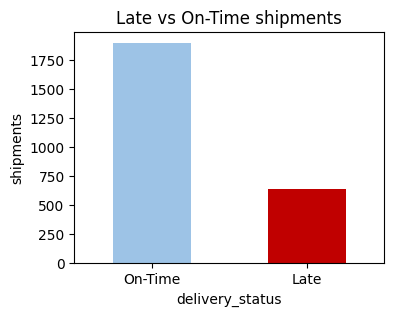

In [9]:

# How many shipments are late?
counts = train_df["delivery_status"].value_counts()
print(counts)
print("Late share:", round(train_df["late"].mean() * 100, 1), "%")

counts.plot(kind="bar", color=["#9DC3E6", "#C00000"], figsize=(4, 3))
plt.title("Late vs On-Time shipments")
plt.ylabel("shipments")
plt.xticks(rotation=0)
plt.show()

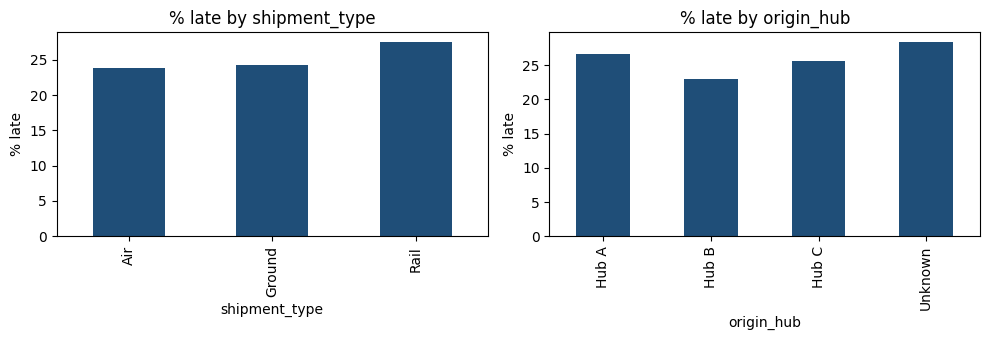

In [10]:
# Late rate by shipment type and origin hub
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, col in zip(axes, ["shipment_type", "origin_hub"]):
    late_rate = train_df.groupby(col)["late"].mean() * 100
    late_rate.plot(kind="bar", ax=ax, color="#1F4E78")
    ax.set_title("% late by " + col)
    ax.set_ylabel("% late")
plt.tight_layout()
plt.show()

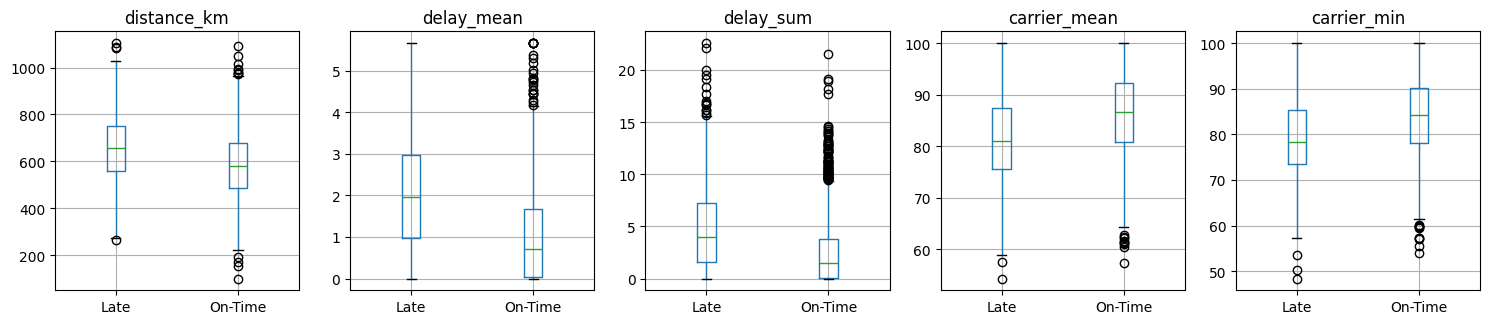

In [11]:
# Do late shipments look different from on-time ones?
cols = ["distance_km", "delay_mean", "delay_sum", "carrier_mean", "carrier_min"]
fig, axes = plt.subplots(1, len(cols), figsize=(15, 3.5))
for ax, col in zip(axes, cols):
    train_df.boxplot(column=col, by="delivery_status", ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("")
plt.tight_layout()
plt.show()

In [12]:
# Correlation of each numeric feature with late
numeric_cols = ["distance_km", "delay_mean", "delay_max", "delay_sum", "log_count",
                "carrier_mean", "carrier_min", "late"]
print(train_df[numeric_cols].corr()["late"].drop("late").round(2).sort_values())

carrier_mean   -0.25
carrier_min    -0.24
log_count      -0.02
distance_km     0.21
delay_sum       0.30
delay_max       0.31
delay_mean      0.34
Name: late, dtype: float64


In [13]:
#Preparing the data and comparing the models
features = pd.get_dummies(data.drop(columns=["shipment_id"]),
                          columns=["shipment_type", "origin_hub"], dtype=int)
features.index = data["shipment_id"]

X = features.loc[train_df["shipment_id"]]
y = train_df["late"].values
X_new = features.loc[pred_df["shipment_id"]]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def make_pipeline(model):
    return Pipeline([
        ("fill", SimpleImputer(strategy="median")),
        ("scale", MinMaxScaler()),
        ("model", model),
    ])

print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (2029, 14) | Test: (508, 14)


Cross-validated ROC-AUC (higher is better):
Logistic Regression    0.765
Random Forest          0.736
Gradient Boosting      0.727
Decision Tree          0.694
dtype: float64


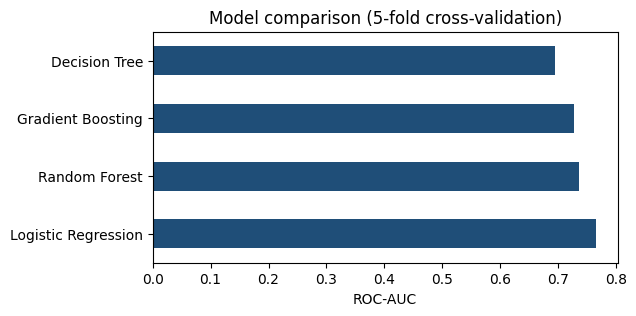

In [14]:
models = {
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, min_samples_leaf=10,
                                            class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                            class_weight="balanced", random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

results = {}
for name, model in models.items():
    scores = cross_val_score(make_pipeline(model), X_train, y_train, cv=cv, scoring="roc_auc")
    results[name] = scores.mean()

results = pd.Series(results).sort_values(ascending=False)
print("Cross-validated ROC-AUC (higher is better):")
print(results.round(3))

results.plot(kind="barh", figsize=(6, 3), color="#1F4E78")
plt.xlabel("ROC-AUC")
plt.title("Model comparison (5-fold cross-validation)")
plt.show()

In [15]:
#Tune the models
param_grids = {
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10]},
    "Decision Tree": {"model__max_depth": [3, 5, 7], "model__min_samples_leaf": [10, 20]},
    "Random Forest": {"model__n_estimators": [100, 200], "model__max_depth": [5, 8, None],
                      "model__min_samples_leaf": [5, 10]},
    "Gradient Boosting": {"model__n_estimators": [50, 100, 200], "model__learning_rate": [0.05, 0.1],
                          "model__max_depth": [2, 3]},
}

tuned_models = {}
tuned_scores = {}
for name, grid in param_grids.items():
    search = GridSearchCV(make_pipeline(models[name]), grid, scoring="roc_auc", cv=cv)
    search.fit(X_train, y_train)
    tuned_models[name] = search.best_estimator_
    tuned_scores[name] = search.best_score_
    print(name, "| best ROC-AUC:", round(search.best_score_, 3), "| best settings:", search.best_params_)

best_name = max(tuned_scores, key=tuned_scores.get)
best_model = tuned_models[best_name]
print("\nBest model:", best_name)

Logistic Regression | best ROC-AUC: 0.765 | best settings: {'model__C': 1}
Decision Tree | best ROC-AUC: 0.717 | best settings: {'model__max_depth': 3, 'model__min_samples_leaf': 20}
Random Forest | best ROC-AUC: 0.752 | best settings: {'model__max_depth': 5, 'model__min_samples_leaf': 10, 'model__n_estimators': 100}
Gradient Boosting | best ROC-AUC: 0.75 | best settings: {'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__n_estimators': 50}

Best model: Logistic Regression


In [16]:
for name, model in tuned_models.items():
    proba = model.predict_proba(X_test)[:, 1]
    print(name, "| test ROC-AUC:", round(roc_auc_score(y_test, proba), 3))

Logistic Regression | test ROC-AUC: 0.788
Decision Tree | test ROC-AUC: 0.762
Random Forest | test ROC-AUC: 0.785
Gradient Boosting | test ROC-AUC: 0.775


In [17]:
TARGET_RECALL = 0.75

# Predicted probabilities for the training data, each from a model that did not see that row
cv_proba = cross_val_predict(best_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

THRESHOLD = 0.10
for t in np.arange(0.70, 0.09, -0.01):
    if recall_score(y_train, cv_proba >= t) >= TARGET_RECALL:
        THRESHOLD = round(t, 2)
        break

print("Chosen threshold:", THRESHOLD)

Chosen threshold: 0.42


              precision    recall  f1-score   support

     On-Time       0.91      0.57      0.70       380
        Late       0.40      0.83      0.54       128

    accuracy                           0.64       508
   macro avg       0.65      0.70      0.62       508
weighted avg       0.78      0.64      0.66       508

ROC-AUC: 0.788


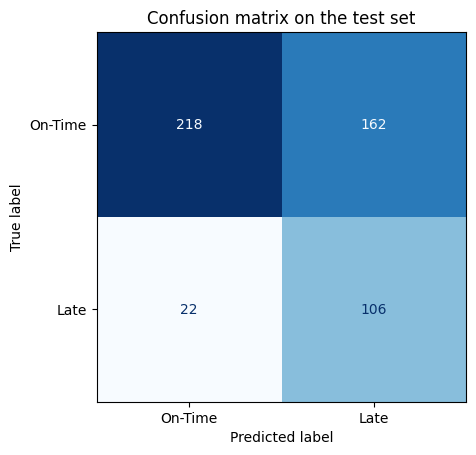

In [18]:
test_proba = best_model.predict_proba(X_test)[:, 1]
y_pred = (test_proba >= THRESHOLD).astype(int)

print(classification_report(y_test, y_pred, target_names=["On-Time", "Late"]))
print("ROC-AUC:", round(roc_auc_score(y_test, test_proba), 3))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["On-Time", "Late"]).plot(cmap="Blues", colorbar=False)
plt.title("Confusion matrix on the test set")
plt.show()

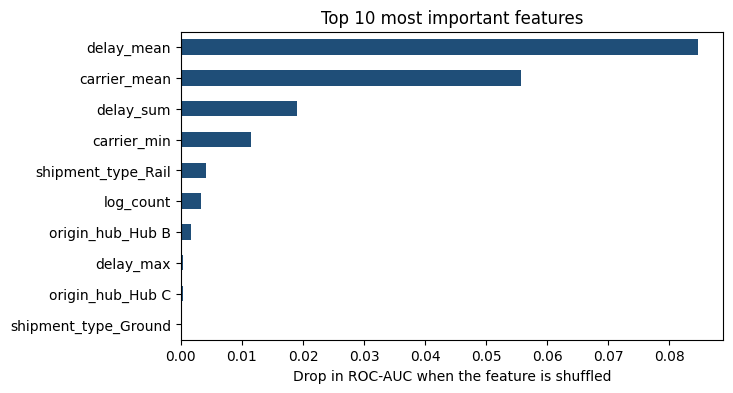

In [19]:
importance = permutation_importance(best_model, X_test, y_test, scoring="roc_auc",
                                    n_repeats=10, random_state=RANDOM_STATE)
top = pd.Series(importance.importances_mean, index=X.columns).sort_values().tail(10)

top.plot(kind="barh", figsize=(7, 4), color="#1F4E78")
plt.xlabel("Drop in ROC-AUC when the feature is shuffled")
plt.title("Top 10 most important features")
plt.show()

In [20]:
# Retrain on all labelled data, then predict the shipments that need predictions
best_model.fit(X, y)
new_proba = best_model.predict_proba(X_new)[:, 1]

output = pd.DataFrame({
    "shipment_id": X_new.index,
    "late_probability": new_proba.round(4),
    "predicted_delivery_status": np.where(new_proba >= THRESHOLD, "Late", "On-Time"),
})
output.to_csv(f"{OUT_DIR}/predictions_final.csv", index=False)

print("Saved", len(output), "predictions")
print(output["predicted_delivery_status"].value_counts())

Saved 447 predictions
predicted_delivery_status
Late       230
On-Time    217
Name: count, dtype: int64
